In [1]:
import os
import cv2
import sys
import copy
import glob
import torch
import torchvision

import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

from pklot_utils import collate_fn, pklot_dataset

%matplotlib inline

In [2]:
root_path = '../dataset/pklot/PKLot'
dataset = pklot_dataset(root_path)

In [3]:
N = len(dataset)
ptest_size = int(.1*N)
valid_size = int(.1*N)
train_size = N - valid_size - ptest_size
train_set, valid_set, ptest_set = torch.utils.data.random_split(dataset, [train_size, valid_size, ptest_size])

kwargs = {
    'num_workers': 4,
    'batch_size' : 8,
    'pin_memory' : True,
    'collate_fn' : collate_fn,
}

train_loader = torch.utils.data.DataLoader(train_set, **kwargs, shuffle=True)
valid_loader = torch.utils.data.DataLoader(valid_set, **kwargs, shuffle=False)
ptest_loader = torch.utils.data.DataLoader(ptest_set, **kwargs, shuffle=False)

In [4]:
print(train_size, valid_size, ptest_size)

9313 1163 1163


In [5]:
sample = iter(train_loader)
images, labels, counts, source, target, contours = next(sample)

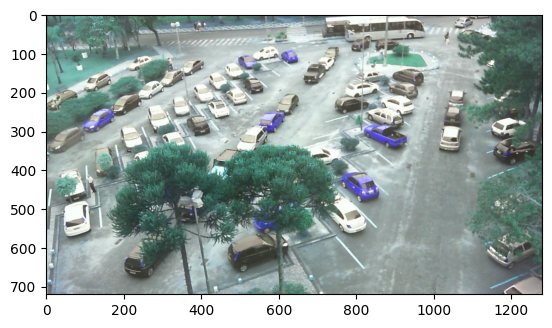

In [6]:
index = 0
image = source[index]
plt.imshow(image)

In [7]:
print(counts[index])
print(labels[index])

[]
tensor([0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
        1, 1, 1, 1])


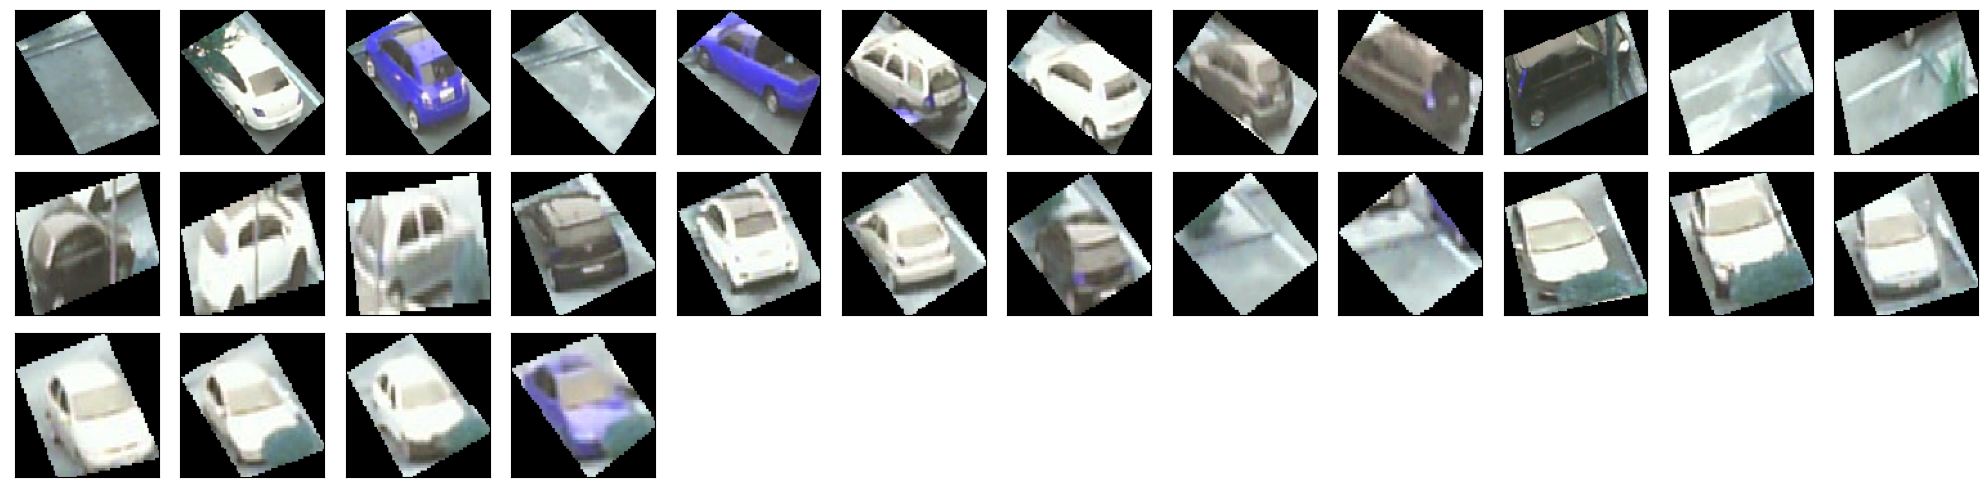

In [12]:
M = 12
N = len(images[index]) // M + 1
fig = plt.figure(figsize=(20,5),facecolor='#FFFFFF') 

for i,frame in enumerate(images[index]):
    ax = fig.add_subplot(N,M,i+1)
    ax.imshow(frame.permute(1,2,0).int())
    #ax.set_title('{},{}'.format(labels[index][i], counts[index][i]))
    ax.set_xticks([])
    ax.set_yticks([])
#plt.suptitle('EuroSAT Image Samples')
plt.tight_layout()
plt.show()

In [ ]:
import torch

a = torch.tensor(1)
print(a)
print(a.tolist())
print(a.item())